Loading installments_payments sample...
Loaded 250,000 installment receipts for 71,096 unique applicants.


All column names and their data types
float64    5
int64      3
Name: count, dtype: int64
Matched with 35,414 applicants in application_train.csv.


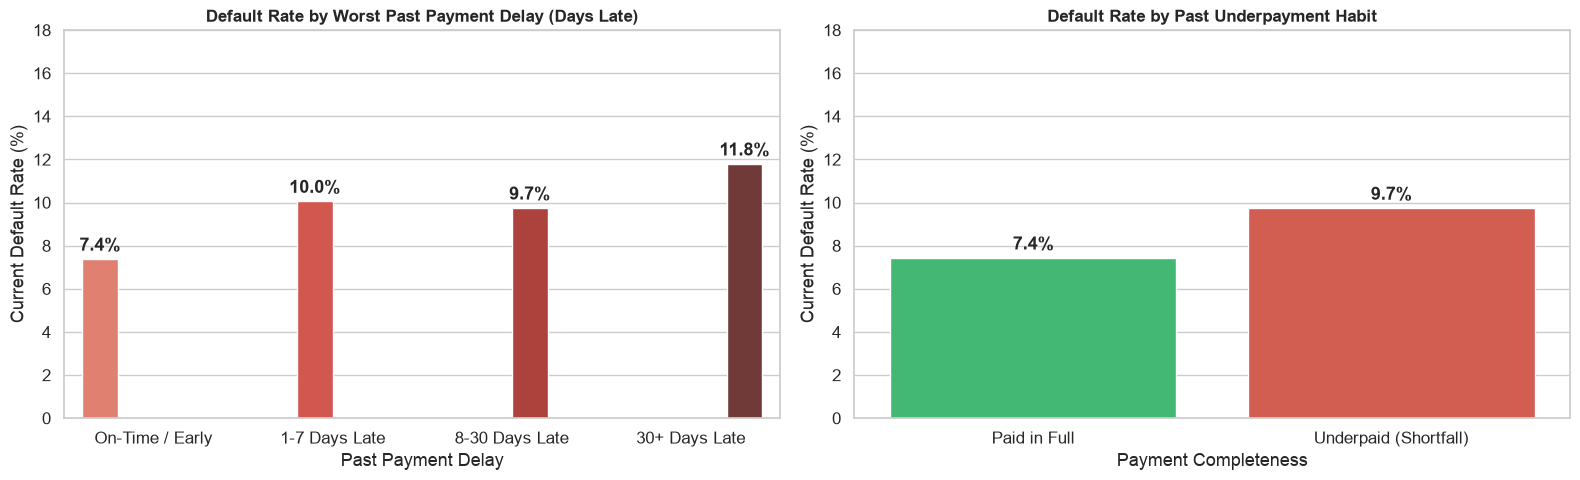

In [4]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)

# Smart Path Finder
data_dir = Path("data") if Path("data").exists() else (Path("../data") if Path("../data").exists() else Path("../../data"))

print("Loading installments_payments sample...")
# Load a 250k row sample for instantaneous, responsive plotting
inst = pd.read_csv(data_dir / "installments_payments.csv", nrows=250000)
app = pd.read_csv(data_dir / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"], nrows=50000)

print(f"Loaded {len(inst):,} installment receipts for {inst['SK_ID_CURR'].nunique():,} unique applicants.")

# all column names and their data types
print("\n\nAll column names and their data types")
print(inst.dtypes.value_counts())

# Check which categorical columns have interesting values
for col in inst.select_dtypes(include=['object', 'str']).columns:
    print(f"\n--- {col} ({inst[col].nunique()} unique categories) ---")
    print(inst[col].value_counts(normalize=True).head(4))

# 1. Feature Engineering on Installments
# Days Late: > 0 means paid late! (clip at 0 so early payments are 0 days late)
inst["DAYS_LATE"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)

# Shortfall: > 0 means underpaid!
inst["SHORTFALL"] = (inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]).clip(lower=0)


# 2. Aggregate per Applicant (1 row per person)
inst_agg = inst.groupby("SK_ID_CURR").agg(
    MAX_DAYS_LATE=("DAYS_LATE", "max"),
    TOTAL_SHORTFALL=("SHORTFALL", "sum")
).reset_index()

# Merge with Target
merged_inst = app.merge(inst_agg, on="SK_ID_CURR", how="inner")
print(f"Matched with {len(merged_inst):,} applicants in application_train.csv.")


# 3. Side-by-Side Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# ─── Panel 1: Days Late vs Current Default Rate ───
merged_inst["LATE_BIN"] = pd.cut(
    merged_inst["MAX_DAYS_LATE"],
    bins=[-1, 0, 7, 30, 500],
    labels=["On-Time / Early", "1-7 Days Late", "8-30 Days Late", "30+ Days Late"]
)
default_by_late = merged_inst.groupby("LATE_BIN", observed=False)["TARGET"].mean() * 100

sns.barplot(
    x=default_by_late.index,
    y=default_by_late.values,
    hue=default_by_late.index,
    palette="Reds_d",
    legend=False,
    ax=ax1
)
ax1.set_title("Default Rate by Worst Past Payment Delay (Days Late)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Past Payment Delay")
ax1.set_ylabel("Current Default Rate (%)")
ax1.set_ylim(0, 18)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontweight="bold")


# ─── Panel 2: Underpayment (Shortfall) vs Current Default Rate ───
merged_inst["HAD_SHORTFALL"] = (merged_inst["TOTAL_SHORTFALL"] > 0).astype(int)
default_by_shortfall = merged_inst.groupby("HAD_SHORTFALL")["TARGET"].mean() * 100
shortfall_labels = ["Paid in Full", "Underpaid (Shortfall)"]

sns.barplot(
    x=shortfall_labels,
    y=default_by_shortfall.values,
    hue=shortfall_labels,
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    ax=ax2
)
ax2.set_title("Default Rate by Past Underpayment Habit", fontsize=12, fontweight="bold")
ax2.set_xlabel("Payment Completeness")
ax2.set_ylabel("Current Default Rate (%)")
ax2.set_ylim(0, 18)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()